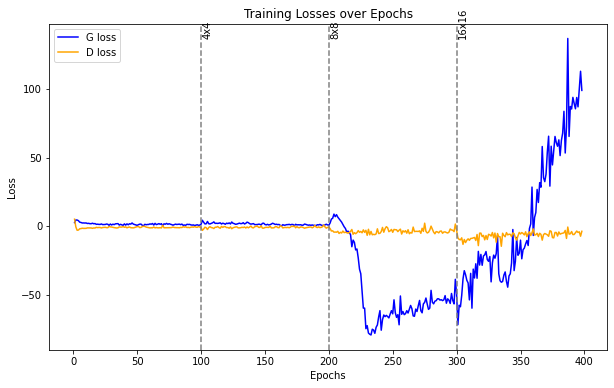

In [1]:
import matplotlib.pyplot as plt

# Inizializziamo le liste per salvare i valori di epoca e le loss
epochs = []
g_losses = []
d_losses = []
vertical_lines = []  # Lista per salvare le posizioni delle linee verticali
resolutions = ["4x4", "8x8", "16x16", "32x32", "64x64", "128x128"]  # Elenco delle risoluzioni
current_resolution = 0  # Indice per tracciare la risoluzione corrente
total_epoch = 0

# Leggi il file riga per riga
with open('./logs/training_log.txt', 'r') as f:
    for line in f:
        # Estrai il numero di epoca e le loss dalla riga
        epoch = int(line.split('Epoch: ')[1].split('/')[0])
         # Se l'epoca si resetta, aggiungi una linea verticale e passa alla prossima risoluzione
        if epoch == 1 and total_epoch > 0:
            vertical_lines.append(total_epoch)
            current_resolution += 1
            
        total_epoch += 1
        # Estrai il G loss e D loss e rimuovi eventuali caratteri indesiderati
        g_loss = float(line.split('G loss: ')[1].split(' ')[0].strip('[]'))
        d_loss = float(line.split('D loss: ')[1].split(']')[0].strip('[]'))
        
        # Aggiungi i valori alle rispettive liste
        epochs.append(total_epoch)
        g_losses.append(g_loss)
        d_losses.append(d_loss)

# Crea il grafico
plt.figure(figsize=(10, 6))
plt.plot(epochs, g_losses, label='G loss', color='blue')
plt.plot(epochs, d_losses, label='D loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Losses over Epochs')
plt.legend()

# Aggiungi linee verticali tratteggiate e etichette per le risoluzioni
for i, vline in enumerate(vertical_lines):
    plt.axvline(x=vline, color='gray', linestyle='--', label=f'Resolution {resolutions[i]}')
    plt.text(vline + 1, max(g_losses + d_losses), resolutions[i], rotation=90, verticalalignment='bottom')

# Salva il grafico come PDF
plt.savefig('training_losses.pdf')

# Mostra il grafico
plt.show()
